LIBRARY

In [120]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import seaborn as sns
import matplotlib.pyplot as plt

FUNCTION

In [121]:
# Fungsi untuk membersihkan data
def clean(data):
    df = pd.DataFrame(columns=['Year', 'Age', 'Female', 'Male', 'Total'])

    for i in range(len(data)):
        row = data.iloc[i, 0].split()
        df.loc[len(df)] = row

    for column in df.columns:
        if df[column].dtype == "object":
            df[column] = df[column].str.replace(r'[+-]', '', regex=True)
    
    for column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce')  # Jika gagal, data menjadi NaN

    df = df.fillna(0)
    df = df.drop_duplicates(subset=["Year", "Age"]).reset_index(drop=True)
    return df

# Fungsi untuk smoothing menggunakan metode Whittaker-Henderson
def whittaker_henderson(y, lambda_, d=2):
    n = len(y)
    E = sp.eye(n)
    D = sp.diags([1, -2, 1], [0, 1, 2], shape=(n - 2, n))
    
    # Matriks penalti
    P = lambda_ * D.T @ D
    
    # Menyelesaikan sistem persamaan
    Z = E + P
    z = spla.spsolve(Z, y)
    
    return z

def calculate_lambda(dx_female, L_female, smoothed_qx_female, t, t0, ages):
    """
    Calculate the lambda_x for each age group using the given formula.

    Parameters:
    dx_female (array): Death counts for females.
    L_female (array): Population counts for females.
    smoothed_qx_female (array): Smoothed qx values (tiled for all years).
    t (array): Year values.
    t0 (int): Initial year.
    ages (array): Array of ages corresponding to dx_female and L_female.

    Returns:
    array: Calculated lambda_x for each age group.
    """
    unique_ages = np.unique(ages)  # Get unique age groups
    lambda_x_list = []

    for age in unique_ages:
        # Filter data for the current age group
        age_mask = (ages == age)  # Mask for current age
        dx = dx_female[age_mask]
        L = L_female[age_mask]
        t_age = t[age_mask]
        qx_t0 = smoothed_qx_female[age]  # Smoothed value for the current age

        # Calculate numerator: ∑_t log(dx / (L * qx_t0)) * (t - t0)
        log_term = np.log(dx / (L * qx_t0))
        numerator = np.sum(log_term * (t_age - t0))

        # Calculate denominator: ∑_t (t - t0)^2
        denominator = np.sum((t_age - t0)**2)

        # Calculate lambda_x for the current age
        lambda_x = -numerator / denominator if denominator != 0 else 0
        lambda_x_list.append(lambda_x)

    return np.array(lambda_x_list)

def calculate_alpha(dx_female, L_female, smoothed_qx_female, lambda_x_values, t, t0, ages):
    """
    Calculate the alpha_t1 for each year using the given formula.

    Parameters:
    dx_female (array): Death counts for females.
    L_female (array): Population counts for females.
    smoothed_qx_female (array): Smoothed qx values (tiled for all years).
    lambda_x_values (array): Array of lambda_x values for each age group.
    t (array): Year values.
    t0 (int): Initial year.
    ages (array): Array of ages corresponding to dx_female and L_female.

    Returns:
    array: Calculated alpha_t1 for each year.
    """
    unique_years = np.unique(t)  # Get unique years
    alpha_t1_list = []

    for year in unique_years:
        # Filter data for the current year
        year_mask = (t == year)
        dx = dx_female[year_mask]
        L = L_female[year_mask]
        qx_t0 = smoothed_qx_female[ages[year_mask]]
        lambda_x = lambda_x_values[ages[year_mask]]

        # Calculate numerator: ∑_x (dx / (L * qx_t0)) * exp(-lambda_x * (t - t0))
        numerator = np.sum((dx / (L * qx_t0)) * np.exp(-lambda_x * (year - t0)))

        # Calculate denominator: ∑_x (exp(-lambda_x * (t - t0)))^2
        denominator = np.sum(np.exp(-lambda_x * (year - t0))**2)

        # Calculate alpha_t1 for the current year
        alpha_t1 = numerator / denominator if denominator != 0 else 0
        alpha_t1_list.append(alpha_t1)

    return np.array(alpha_t1_list)

def calculate_qx(alpha_t1, smoothed_qx_female, lambda_x_values, t, t0, ages):
    """
    Calculate the q_{x,t} for each age and year using the given formula.

    Parameters:
    alpha_t1 (array): Array of alpha_t1 values for each year.
    smoothed_qx_female (array): Smoothed qx values (one for each age group at t0).
    lambda_x_values (array): Lambda_x values for each age group.
    t (array): Year values.
    t0 (int): Initial year.
    ages (array): Array of ages corresponding to qx.

    Returns:
    array: Calculated q_{x,t} values for each age and year.
    """
    # Create an array to store the results
    qx_t = np.zeros_like(t, dtype=float)

    for i, year in enumerate(np.unique(t)):  # Iterate over each unique year
        year_mask = (t == year)  # Select data for the current year
        alpha = alpha_t1[i]  # Alpha value for the current year
        age_indices = ages[year_mask]
        
        # Calculate q_{x,t} for the current year
        qx_t[year_mask] = alpha * smoothed_qx_female[age_indices] * np.exp(-lambda_x_values[age_indices] * (year - t0))

    return qx_t

DATA

In [122]:
# Membaca dan membersihkan data
italy_death = clean(pd.read_csv("Data pembanding/Italy/Italy , Deaths (period 1x1).txt", delimiter="\t"))
italy_population = clean(pd.read_csv("Data pembanding/Italy/Italy , Population size (abridged).txt", delimiter="\t"))

BACKUP

In [123]:
backup_bel_death = italy_death.copy()
backup_bel_population = italy_population.copy()

# Mengatur data agar memiliki panjang yang sama
selisih = len(italy_population) - len(italy_death)
backup_bel_population = backup_bel_population[:-selisih].reset_index(drop=True)

backup_bel_death = backup_bel_death[backup_bel_death["Age"] < 104].reset_index(drop=True)
backup_bel_population = backup_bel_population[backup_bel_population["Age"] < 104].reset_index(drop=True)


FEMALE

WHITE TAKER

In [124]:
# Menghitung qx untuk perempuan
qx_female = (backup_bel_death["Female"] / backup_bel_population["Female"]).fillna(0)

# Smoothing qx menggunakan Whittaker-Henderson
qx_head_female = qx_female.head(111)
qx_1841_female = qx_head_female[:-7]
smoothed_qx_female = whittaker_henderson(qx_1841_female, lambda_=10)
smoothed_qx_female

array([0.22823646, 0.16968367, 0.11709967, 0.07518509, 0.04480281,
       0.0247071 , 0.01262449, 0.00620222, 0.00347223, 0.00294605,
       0.00354608, 0.00457082, 0.00555839, 0.00636554, 0.00692921,
       0.00731522, 0.00761167, 0.0078952 , 0.00821041, 0.00861125,
       0.00904824, 0.00954668, 0.00997198, 0.0103259 , 0.01059356,
       0.01084018, 0.01112031, 0.01143201, 0.01174291, 0.01205788,
       0.01226627, 0.01258788, 0.01273264, 0.01276554, 0.01270178,
       0.01267871, 0.01285831, 0.01319839, 0.01353386, 0.01382121,
       0.0139419 , 0.01426751, 0.01440638, 0.01440696, 0.01423217,
       0.01412075, 0.0143386 , 0.01480123, 0.01541382, 0.01623326,
       0.01721401, 0.01876616, 0.0203057 , 0.02177548, 0.0230358 ,
       0.02444128, 0.02636284, 0.02872431, 0.03123125, 0.0339422 ,
       0.03676669, 0.04084773, 0.04491867, 0.04884328, 0.05253099,
       0.05671075, 0.06214793, 0.06819516, 0.07406671, 0.07979577,
       0.08569313, 0.09490199, 0.10521493, 0.11607408, 0.12620

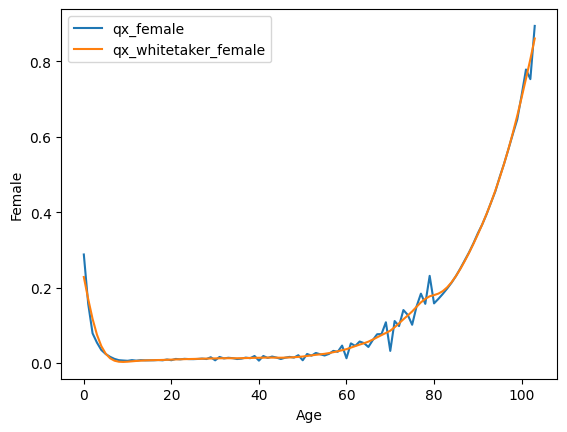

In [125]:
age = backup_bel_death["Age"].head(104)

sns.lineplot(x = age, y = qx_1841_female, label = "qx_female")
sns.lineplot(x = age, y = smoothed_qx_female, label = "qx_whitetaker_female")
plt.legend()

LAMBDA

In [126]:
# Prepare the data
ages = backup_bel_death["Age"].values  # Assuming the dataset has an 'Age' column

# Call the function
lambda_female = calculate_lambda(
    dx_female=backup_bel_death["Female"].values,
    L_female=backup_bel_population["Female"].values,
    smoothed_qx_female=smoothed_qx_female,
    t=backup_bel_death["Year"].values,
    t0=1872,
    ages=ages
)

# Replace NaN and infinity values with 0
lambda_female = np.nan_to_num(lambda_female, nan=0, posinf=0, neginf=0)

# Print the result
print(lambda_female)


[0.02562809 0.04509447 0.04766004 0.04669908 0.04416125 0.04006873
 0.03418295 0.02882465 0.02415295 0.0229376  0.02494717 0.02734332
 0.02859383 0.0291702  0.02845955 0.02791324 0.02737107 0.0269702
 0.0263482  0.02651347 0.02658752 0.02694789 0.02719363 0.02737732
 0.02726571 0.02710585 0.02725521 0.02715364 0.02707323 0.02687068
 0.02654856 0.02644388 0.02591247 0.02542103 0.02470305 0.0240411
 0.02355628 0.02319391 0.02261383 0.0223132  0.02147435 0.02114403
 0.02044714 0.01975972 0.01888017 0.01798342 0.01735524 0.01689589
 0.01642923 0.01612246 0.01572916 0.01584082 0.01574819 0.01573176
 0.01547815 0.01533601 0.01525013 0.01526122 0.01519081 0.01507732
 0.0147622  0.01495675 0.01487174 0.01476351 0.01448169 0.01423604
 0.01418774 0.01409044 0.01384941 0.013514   0.01296226 0.01294491
 0.01277173 0.01261445 0.0122872  0.01188224 0.01159489 0.01120214
 0.01052835 0.00971645 0.00883284 0.0079389  0.007031   0.00637162
 0.00585588 0.00551198 0.00520348 0.00500116 0.00474212 0.004464

/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_1350/2853477387.py:62: RuntimeWarning: divide by zero encountered in divide
  log_term = np.log(dx / (L * qx_t0))
/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_1350/2853477387.py:62: RuntimeWarning: divide by zero encountered in log
  log_term = np.log(dx / (L * qx_t0))
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


ALPHA

In [127]:
# Calculate alpha_t1 values for each year
alpha_female = calculate_alpha(
    dx_female=backup_bel_death["Female"].values,
    L_female=backup_bel_population["Female"].values,
    smoothed_qx_female=smoothed_qx_female,
    lambda_x_values=lambda_female,
    t=backup_bel_death["Year"].values,
    t0=1872,
    ages=ages
)

# Replace NaN and infinity values in alpha_female
alpha_female = np.nan_to_num(alpha_female, nan=0, posinf=0, neginf=0)

print(alpha_female)

[1.04247837 1.06003148 1.0973187  1.10769081 1.02567178 1.03176813
 1.04782536 1.08274811 1.11604783 0.99041101 0.99860957 1.08885239
 1.08900515 1.07873336 1.19703263 1.18198345 1.19409748 1.14723055
 1.23845384 1.24237231 0.         0.         0.         0.
 1.12168169 1.03722907 1.05115643 1.10336831 1.20921712 1.14445489
 1.1617512  1.12006842 1.04790241 1.17202078 1.10088938 1.15160144
 1.23936517 1.22738662 1.14374302 1.27069706 1.08599735 1.11602649
 1.1151524  1.25392097 1.22781052 1.30991494 2.14925562 1.38379049
 1.28592127 1.22331219 1.30377235 1.16739974 1.26617192 1.25359201
 1.2969956  1.30228197 1.30177948 1.36681383 1.09952114 1.19881675
 1.22166599 1.17782224 1.14851774 1.2485308  1.21364658 1.27036843
 1.31748755 1.27836917 1.34762592 1.31949239 1.38192545 1.44037074
 1.49307661 1.38191723 1.22564825 1.18639212 1.17415234 1.1735638
 1.12435691 1.14663863 1.15136085 1.16660418 1.08566471 1.08531347
 1.22376503 1.1081422  1.07715251 1.02033973 1.09171504 1.04357681
 1.1

/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_1350/2853477387.py:102: RuntimeWarning: divide by zero encountered in divide
  numerator = np.sum((dx / (L * qx_t0)) * np.exp(-lambda_x * (year - t0)))


QX

In [128]:
# Calculate q_{x,t}
qx_female = calculate_qx(
    alpha_t1=alpha_female,
    smoothed_qx_female=smoothed_qx_female,
    lambda_x_values=lambda_female,
    t=backup_bel_death["Year"].values,
    t0=1872,
    ages=ages
)

# Replace NaN and infinity values
qx_female = np.nan_to_num(qx_female, nan=0, posinf=0, neginf=0)

# Print the results
print(qx_female)

[0.23793158 0.17689156 0.12207387 ... 0.37064135 0.39075515 0.72536922]


In [129]:
ages = backup_bel_death['Age'].unique() 
tahun = np.arange(0, 150)
t0 = 1872

# Create a DataFrame for qx values
qx_df = pd.DataFrame({
    'Age': np.repeat(ages, len(tahun)),  # Repeat each age for all years
    'Year': np.tile(tahun + t0, len(ages)),  # Adjust years to match the actual range
    'qx': qx_female  # Ensure qx_female matches the length of the repeated ages and years
})

# Merge qx_df into backup_bel_death to align with available combinations
tabel = pd.merge(
    backup_bel_death[['Age', 'Year']], 
    qx_df, 
    on=['Age', 'Year'], 
    how='left'
)

# Create the pivot table
pivot_table = tabel.pivot(index='Age', columns='Year', values='qx')

# Fill missing values in the pivot table with 0 (if desired)
pivot_table = pivot_table.fillna(0)

# Display the pivot table
pivot_table

Year,1872,1873,1874,1875,1876,1877,1878,1879,1880,1881,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
Age,,,,,,,,,,,,,,,,,,,,,
0,0.237932,0.176892,0.122074,0.078379,0.046706,0.025757,0.013161,0.006466,0.003620,0.003071,...,0.013313,0.013670,0.014026,0.014328,0.014465,0.014808,0.014962,0.014973,0.014804,0.014702
1,0.014938,0.015427,0.016073,0.016933,0.017963,0.019580,0.021188,0.022722,0.024044,0.025514,...,0.206393,0.217564,0.232333,0.250260,0.270854,0.293531,0.317960,0.343920,0.371249,0.399973
2,0.430555,0.463208,0.498168,0.535727,0.576062,0.618933,0.665049,0.714814,0.767131,0.821603,...,0.009743,0.009976,0.010228,0.010519,0.010808,0.011107,0.011314,0.011615,0.011774,0.011827
3,0.011802,0.011812,0.012002,0.012338,0.012681,0.012966,0.013123,0.013447,0.013616,0.013654,...,0.082867,0.091780,0.101842,0.112441,0.122452,0.132975,0.145160,0.157008,0.166591,0.173962
4,0.177909,0.182568,0.190013,0.200695,0.214650,0.231451,0.250730,0.271886,0.294743,0.319073,...,0.004927,0.005619,0.006147,0.006515,0.006805,0.007078,0.007393,0.007744,0.008133,0.008560
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,0.054065,0.062503,0.071744,0.081091,0.091638,0.102163,0.114753,0.129044,0.143456,0.157474,...,0.000090,0.000103,0.000116,0.000128,0.000145,0.000149,0.000155,0.000155,0.000156,0.000158
100,0.000164,0.000172,0.000173,0.000180,0.000187,0.000198,0.000211,0.000220,0.000240,0.000258,...,0.003543,0.003827,0.004261,0.004706,0.005273,0.005899,0.006510,0.007245,0.008148,0.009216
101,0.010721,0.011904,0.013533,0.015274,0.017413,0.020013,0.022744,0.025990,0.030305,0.035455,...,0.000084,0.000062,0.000054,0.000054,0.000066,0.000071,0.000079,0.000080,0.000072,0.000065


DEATH RATES

In [130]:
italy_death_rates = clean(pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/dyah_putri/Data pembanding/Italy/Italy , Death rates (period 1x1),.txt", delimiter="\t"))
italy_death_rates[["Year", "Age"]] = italy_death_rates[["Year", "Age"]].astype(int)
italy_death_rates = italy_death_rates.drop([0]).reset_index(drop=True)

# Extract 2020 and 2021 data
italy_2020 = italy_death_rates[16428:16532]
italy_2021 = italy_death_rates[16539:16643]

PERBANDINGAN TAHUN 2020

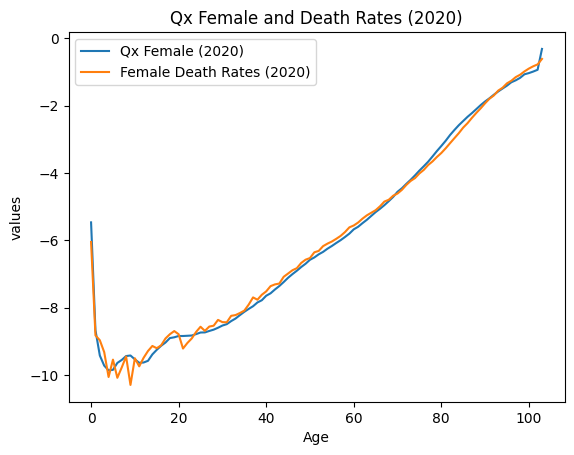

In [158]:
# Plot perbandingan qx_female_final dan death rates 2021
age = italy_2021["Age"].values
sns.lineplot(x=age, y=(np.log(qx_female[15496:15600])), label="Qx Female (2020)")
sns.lineplot(x=age, y=(np.log(italy_2021["Female"].values)), label="Female Death Rates (2020)")

plt.legend()
plt.xlabel("Age")
plt.ylabel("values")
plt.title("Qx Female and Death Rates (2020)")
plt.show()

ARIMA

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=-46.850, Time=0.19 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=-26.600, Time=0.01 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=-24.681, Time=0.00 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=-24.648, Time=0.00 sec
 ARIMA(1,0,2)(0,0,0)[0]             : AIC=-33.009, Time=0.01 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=-34.557, Time=0.01 sec
 ARIMA(3,0,2)(0,0,0)[0]             : AIC=-61.409, Time=0.05 sec
 ARIMA(3,0,1)(0,0,0)[0]             : AIC=-32.553, Time=0.01 sec
 ARIMA(4,0,2)(0,0,0)[0]             : AIC=inf, Time=0.06 sec
 ARIMA(3,0,3)(0,0,0)[0]             : AIC=inf, Time=0.06 sec
 ARIMA(2,0,3)(0,0,0)[0]             : AIC=inf, Time=0.04 sec
 ARIMA(4,0,1)(0,0,0)[0]             : AIC=-42.801, Time=0.04 sec
 ARIMA(4,0,3)(0,0,0)[0]             : AIC=-47.646, Time=0.06 sec
 ARIMA(3,0,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.06 sec

Best model:  ARIMA(3,0,2)(0,0,0)[0]          
Total fit time: 

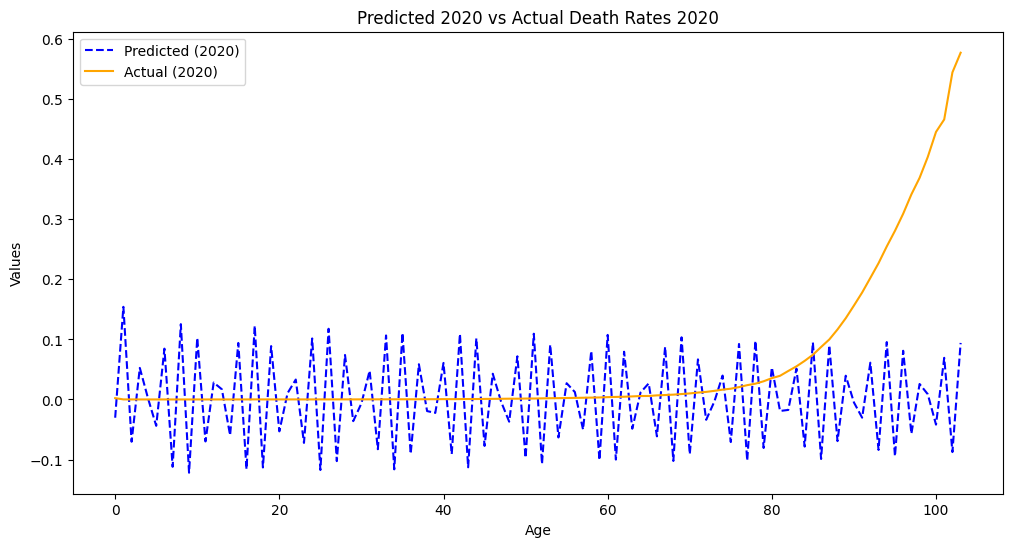

In [162]:
from pmdarima import auto_arima
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Extract qx female values for 2019
qx_female_2019 = pivot_table[2019].values

# Fit ARIMA to qx_female_2019
arima_2019 = auto_arima(
    qx_female_2019,
    seasonal=False,
    trace=True,
    error_action='ignore',
    suppress_warnings=True
)

print(f"Best order selected by auto_arima: {arima_2019.order}")

# Forecast qx values for 2020
forecast_2020 = arima_2019.predict(n_periods=104)

# Extract actual qx values for 2020 (Italy dataset)
italy_2020_female = italy_2020["Female"].values

# Get age values for plotting
age_2020 = italy_2020["Age"].values

# Plotting
plt.figure(figsize=(12, 6))

# Plot predicted qx values for 2020
sns.lineplot(x=age_2020, y= forecast_2020, color="blue", linestyle="--", label="Predicted (2020)")

# Plot actual qx values for 2020
sns.lineplot(x=age_2020, y= italy_2020_female, color="orange", label="Actual (2020)")

# Add labels and title
plt.xlabel("Age")
plt.ylabel("Values")
plt.title("Predicted 2020 vs Actual Death Rates 2020")

# Show legend
plt.legend()
plt.show()


In [138]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(italy_2020_female, forecast_2020)
rmse = np.sqrt(mean_squared_error(italy_2020_female, forecast_2020))
print(f"MAE: {mae:.5f}, RMSE: {rmse:.5f}")

MAE: 0.10941, RMSE: 0.15543


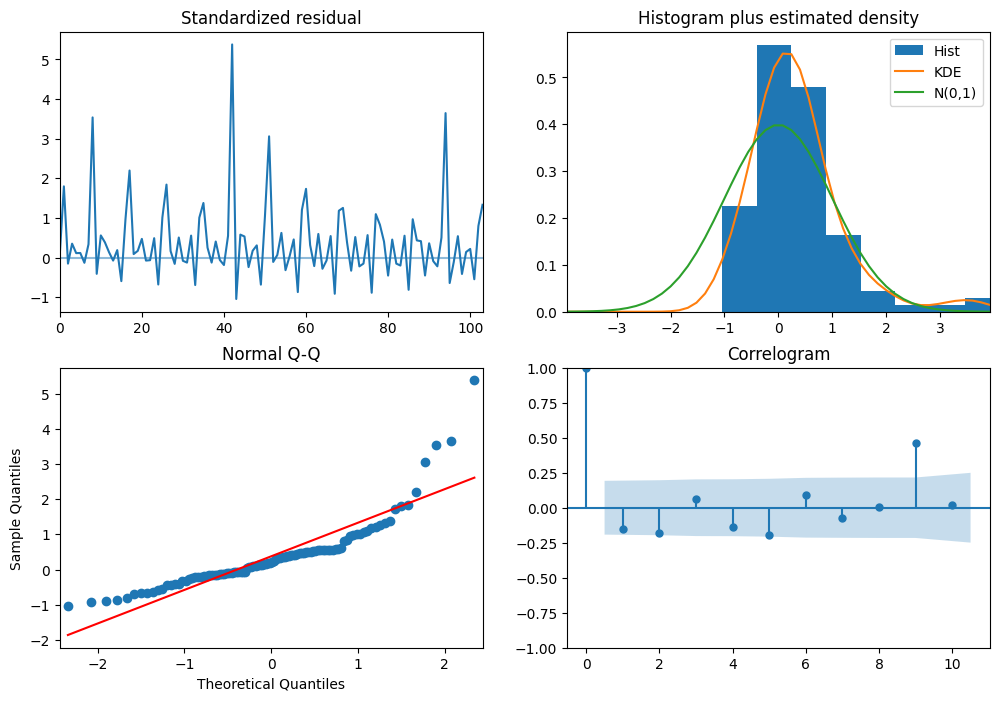

In [137]:
arima_2019.plot_diagnostics(figsize=(12, 8))
plt.show()